## Setup

In [ ]:
%%capture
!pip install update tensorflow
!pip install  tensorflow-text tensorflow-hub

import locale
locale.getpreferredencoding = lambda: "UTF-8"
import keras
import pandas as pd
import os
import sentencepiece as spm
import numpy as np
import re
import tensorflow_text as tf_text
import tensorflow as tf
import requests
import math
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow_hub as hub
import plotly.express as px
import tensorflow_datasets as tfds
import random


from tensorflow.data.experimental import make_csv_dataset
from keras import layers
from sklearn.preprocessing import LabelEncoder
from keras.utils import to_categorical
from sklearn.utils import compute_class_weight

from tqdm import tqdm

from transformers import BertTokenizer, AutoTokenizer

tf.compat.v1.enable_v2_behavior()
tqdm.pandas()

sns.set_style("darkgrid")
plt.rcParams['figure.figsize'] = (20,8)
plt.rcParams['font.size'] = 18



## Implement Transformer

In [ ]:
from tensorflow import math, cast, float32, linalg, ones, maximum, newaxis

class TransformerBlock(layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, rate=0.1):
        super().__init__()
        self.att = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.ffn = keras.Sequential(
            [layers.Dense(ff_dim, activation="sigmoid"), layers.Dense(embed_dim),]
        )
        self.layernorm1 = layers.LayerNormalization(epsilon=1e-9)
        self.layernorm2 = layers.LayerNormalization(epsilon=1e-9)
        self.dropout1 = layers.Dropout(rate)
        self.dropout2 = layers.Dropout(rate)



    def call(self, inputs):
        attn_output = self.att(inputs, inputs, inputs)
        attn_output = self.dropout1(attn_output)
        out1 = self.layernorm1(inputs + attn_output)
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output)
        return self.layernorm2(out1 + ffn_output)

## Implementing embedding layer

In [ ]:
def positional_encoding(length, depth):
  depth = depth/2

  positions = np.arange(length)[:, np.newaxis]     # (seq, 1)
  depths = np.arange(depth)[np.newaxis, :]/depth   # (1, depth)

  angle_rates = 1 / (10000**depths)         # (1, depth)
  angle_rads = positions * angle_rates      # (pos, depth)

  pos_encoding = np.concatenate(
      [np.sin(angle_rads), np.cos(angle_rads)],
      axis=-1)

  return tf.cast(pos_encoding, dtype=tf.float32)

class PositionalEmbedding(tf.keras.layers.Layer):#we would not have meaning of word without positional embedding
  def __init__(self, vocab_size, d_model, mask_zero=True):
    super().__init__()
    self.d_model = d_model
    self.embedding = tf.keras.layers.Embedding(vocab_size, d_model, mask_zero=mask_zero)
    self.pos_encoding = positional_encoding(length=2048, depth=d_model)


  def call(self, x):
    length = tf.shape(x)[1]
    x = self.embedding(x)
    # This factor sets the relative scale of the embedding and positonal_encoding.
    x *= tf.math.sqrt(tf.cast(self.d_model, tf.float32))
    x = x + self.pos_encoding[tf.newaxis, :length, :]
    return x


## Tokenization and embedding

### Setup

### Read data from file

In [ ]:
to_download = 0 #If you want to get from the internet the required files
try:
  from google.colab import drive
  drive.mount('/content/drive')
  dir = "/content/drive/MyDrive/HLT project/Project files/sentiment_annotated_with_texts.csv"

except ModuleNotFoundError:
  if not to_download:
    dir = "/home/lesi-nedo/Desktop/master/second-semester/HLT/project/sentiment_annotated_with_texts.csv"
  else:
    if not os. path. exists("sentiment_annotated_with_texts.csv?download=1"):
      !wget https://zenodo.org/records/7976208/files/sentiment_annotated_with_texts.csv?download=1
      dir = "sentiment_annotated_with_texts.csv?download=1"

Mounted at /content/drive


In [ ]:
config = {
  'seed': 37,
  'batch_size': 64,
  'epochs': 36,
  'max_seq_len': 728
}

#### Extracts only 'text' and 'true_sentiment' from csv file

In [ ]:


le = LabelEncoder()


sent_o = pd.read_csv(dir, delimiter=',', quotechar='"')






sent_o = sent_o [['text', 'true_sentiment']]
sent1 = sent_o
sent1.reset_index(drop=True, inplace=True)
sent1[:10]



,text,true_sentiment
0,The Euro was able to appreciate particularly s...,Positive
1,EUR/CHF yesterday broke above 1.00. Economists...,Positive
2,EUR/CHF vaults parity for the first time since...,Neutral
3,EUR/CHF climbs back above parity. Economists a...,Positive
4,EUR/CHF has broken out above the sideways rang...,Positive
5,Analysts at MUFG Bank have a bullish outlook f...,Positive
6,The USDCHF is sharply higher on the day helped...,Neutral
7,"The EURCHF is up for the 5th day in a row, aft...",Positive
8,Economists at Credit Suisse are now neutral o...,Negative
9,New low for the EURUSD as it remains the curre...,Negative


### Transforms the Dataframe in DataSet

In [ ]:


sent = {'text': sent1['text'], 'target': sent1['true_sentiment']}

dict_labels = {0: 'Negative', 1: 'Positive', 2: 'Positive'}
print(sent['target'][:9])
sent['target'] = to_categorical(le.fit_transform(sent['target']), num_classes=3).astype(np.int32)
print(sent['target'][:9])

classWeight = compute_class_weight(class_weight='balanced', classes=np.unique(sent1['true_sentiment']), y=sent1['true_sentiment'])

tf.data.experimental.enable_debug_mode()

dataset = tf.data.Dataset.from_tensor_slices(sent).shuffle(1024)

dataset_size =  dataset.cardinality().numpy()
dataset_size

0    Positive
1    Positive
2     Neutral
3    Positive
4    Positive
5    Positive
6     Neutral
7    Positive
8    Negative
Name: true_sentiment, dtype: object
[[0 0 1]
 [0 0 1]
 [0 1 0]
 [0 0 1]
 [0 0 1]
 [0 0 1]
 [0 1 0]
 [0 0 1]
 [1 0 0]]


2291

### Gets the pre-trained LLama model for tokenization

In [ ]:


hf_tok = AutoTokenizer.from_pretrained("codellama/CodeLlama-7b-Python-hf", trust_remote_code=True)

if hf_tok.pad_token is None:
    hf_tok.add_special_tokens({'pad_token': '[PAD]'})



/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/749 [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

### Transforms text into tokens, truncates and pads

In [ ]:

def preprocess(news, label):
  ids = preprocess_input(news)
  return ids, label

def preprocess_input(review):
  ids = tokenize_text(review, config['max_seq_len'])
  return ids

def tokenize_text(news, seq_len):

  tokens = hf_tok.encode(news.numpy().decode())
  sent_len = len(tokens)
  if sent_len > seq_len:
    tokens = tokens[:seq_len]
  elif sent_len < seq_len:
    tokens += [0] * (seq_len - sent_len)
  return tokens


### Splits the data set

In [ ]:
train_size = int(0.7 * dataset_size)
val_size = int(0.15 * dataset_size)
test_size = int(0.15 * dataset_size)


train_dataset = dataset.take(train_size)
test_dataset = dataset.skip(train_size)
val_dataset = test_dataset.skip(val_size)
test_dataset = test_dataset.take(test_size)





### Apply the acctual preprocess function and reshape the dataset

In [ ]:
def data_rescale(y_dim, d):
  return tf.ensure_shape(d, y_dim)

tf.config.run_functions_eagerly(True)#using multithreading ; one tensor with text and true sentiment
train_ds = train_dataset.map(lambda x: tf.py_function(preprocess, [x['text'], x['target']], [tf.int32, tf.int32]),num_parallel_calls=tf.data.AUTOTUNE)
valid_ds = val_dataset.map(lambda x: tf.py_function(preprocess, [x['text'], x['target']], [tf.int32, tf.int32]),num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_dataset.map(lambda x: tf.py_function(preprocess, [x['text'], x['target']], [tf.int32, tf.int32]),num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.map(lambda ne,le: (data_rescale(config['max_seq_len'], ne), data_rescale(3, le)))
valid_ds = valid_ds.map(lambda ne,le: (data_rescale(config['max_seq_len'], ne), data_rescale(3, le)))
test_ds = test_ds.map(lambda ne,le: (data_rescale(config['max_seq_len'], ne), data_rescale(3, le)))


train_ds = train_ds.shuffle(1024).batch(config['batch_size']).prefetch(tf.data.experimental.AUTOTUNE)
valid_ds = valid_ds.shuffle(1024).batch(config['batch_size']).prefetch(tf.data.experimental.AUTOTUNE)
test_ds = test_ds.shuffle(1024).batch(config['batch_size']).prefetch(tf.data.experimental.AUTOTUNE)

In [ ]:
ds_numpy = tfds.as_numpy(train_ds)
for ex in ds_numpy:
  print("Encode and Decode --- {}\n{}".format(ex[0][0],hf_tok.decode(ex[0][0])))
  print("Shape of input --- {}".format(ex[0].shape))
  print("Shape of label --- {}".format(ex[1].shape))
  print("Vocab size --- {}".format(hf_tok.vocab_size))
  break

Encode and Decode --- [    1  2266   338   825   366   817   304  1073   373   323  1041  3250
 29892  4779 29871 29906 29896 29901 14406  7103   923 14561   278  4723
   355 30010 29879  9763   313  7466 29903  1321  5414 24596   277 27968
   322  6615   630  6555  9124  3158   467   450 26028 10920 17515   901
  1135 29871 29896 15543  3148 17498  9698 12151  1156 29425 10849  4098
   368   301  1242 29892   411   278  3148 29871 29896 29900 29899  6360
  7709   337  9917   292 11183 29871 29941 29889 29945 29900 15543   450
   315  8456 29923 13072   271  1793  3220   313 29963  6415 29897 13700
   491  4359 29871 29953 13667  1550   278  3308   360 26810 11374 29888
   514   491 29871 29900 29889 29945 29946 13667 16742   278 19604  3802
   297   263  4098 29889 28297 29916  9999 10049   287   304   278 20414
   297  9999 19688 29889 10682  1860   297   278  9124   292 17535   322
   278 14879 27811 30010 29879 11781   674   367   263  1820  7156   363
   278  2446 21396 29889   45

## Prepare the embedding

In [ ]:
embed_dim = 32  # Embedding size for each token
num_heads = 8  # Number of attention heads
ff_dim = 128 # Hidden layer size in feed forward network inside transformer

inputs = layers.Input(shape=(config['max_seq_len'],))
embedding_layer = PositionalEmbedding(hf_tok.vocab_size, embed_dim, mask_zero=True)
x = embedding_layer(inputs)
transformer_block = TransformerBlock(embed_dim, num_heads, ff_dim)
x = transformer_block(x)#passing data
x = layers.GlobalAveragePooling1D()(x)#reduce dimension
x = layers.Dense(ff_dim, activation="sigmoid")(x)
x = layers.Dropout(0.1)(x)
outputs = layers.Dense(units=3, activation="softmax")(x)

model = keras.Model(inputs=inputs, outputs=outputs)

## Train and Evaluate

#### Model train

In [ ]:


optimizer = tf.keras.optimizers.Adam(learning_rate=5e-10,epsilon=1e-12,clipnorm=1.0)



model.compile(
    optimizer=optimizer, loss=tf.keras.losses.CategoricalCrossentropy(), metrics=["accuracy"],
    )

model.summary()


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 728)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ positional_embedding                 │ (None, 728, 32)             │       1,024,000 │
│ (PositionalEmbedding)                │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ transformer_block (TransformerBlock) │ (None, 728, 32)             │          42,048 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d             │ (None, 32)                  │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │           4,224 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,070,659 (4.08 MB)

 Trainable params: 1,070,659 (4.08 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
callbacks = [
  # EarlyStopping: Stop training when a val_loss stops improving
  keras.callbacks.EarlyStopping(
    min_delta = 0.001,
    patience = 15,
    monitor = 'val_loss',
    mode = 'min',
    restore_best_weights = True
  ),
]
print(train_ds.element_spec)

history = model.fit(
    train_ds, epochs=config['epochs'], validation_data=valid_ds, callbacks=callbacks, class_weight= dict(enumerate(classWeight))
)

(TensorSpec(shape=(None, 728), dtype=tf.int32, name=None), TensorSpec(shape=(None, 3), dtype=tf.int32, name=None))
Epoch 1/36
26/26 ━━━━━━━━━━━━━━━━━━━━ 37s 789ms/step - accuracy: 0.3180 - loss: 1.1214 - val_accuracy: 0.3043 - val_loss: 1.1114
Epoch 2/36
26/26 ━━━━━━━━━━━━━━━━━━━━ 18s 468ms/step - accuracy: 0.3367 - loss: 1.1212 - val_accuracy: 0.3130 - val_loss: 1.1092
Epoch 3/36
26/26 ━━━━━━━━━━━━━━━━━━━━ 15s 459ms/step - accuracy: 0.3157 - loss: 1.1301 - val_accuracy: 0.3130 - val_loss: 1.1085
Epoch 4/36
26/26 ━━━━━━━━━━━━━━━━━━━━ 15s 456ms/step - accuracy: 0.3563 - loss: 1.1193 - val_accuracy: 0.3159 - val_loss: 1.1092
Epoch 5/36
26/26 ━━━━━━━━━━━━━━━━━━━━ 15s 453ms/step - accuracy: 0.3324 - loss: 1.1172 - val_accuracy: 0.3072 - val_loss: 1.1114
Epoch 6/36
26/26 ━━━━━━━━━━━━━━━━━━━━ 15s 458ms/step - accuracy: 0.3307 - loss: 1.1194 - val_accuracy: 0.2957 - val_loss: 1.1130
Epoch 7/36
26/26 ━━━━━━━━━━━━━━━━━━━━ 16s 445ms/step - accuracy: 0.3055 - loss: 1.1264 - val_accuracy: 0.3072 -

#### Model Evaluate

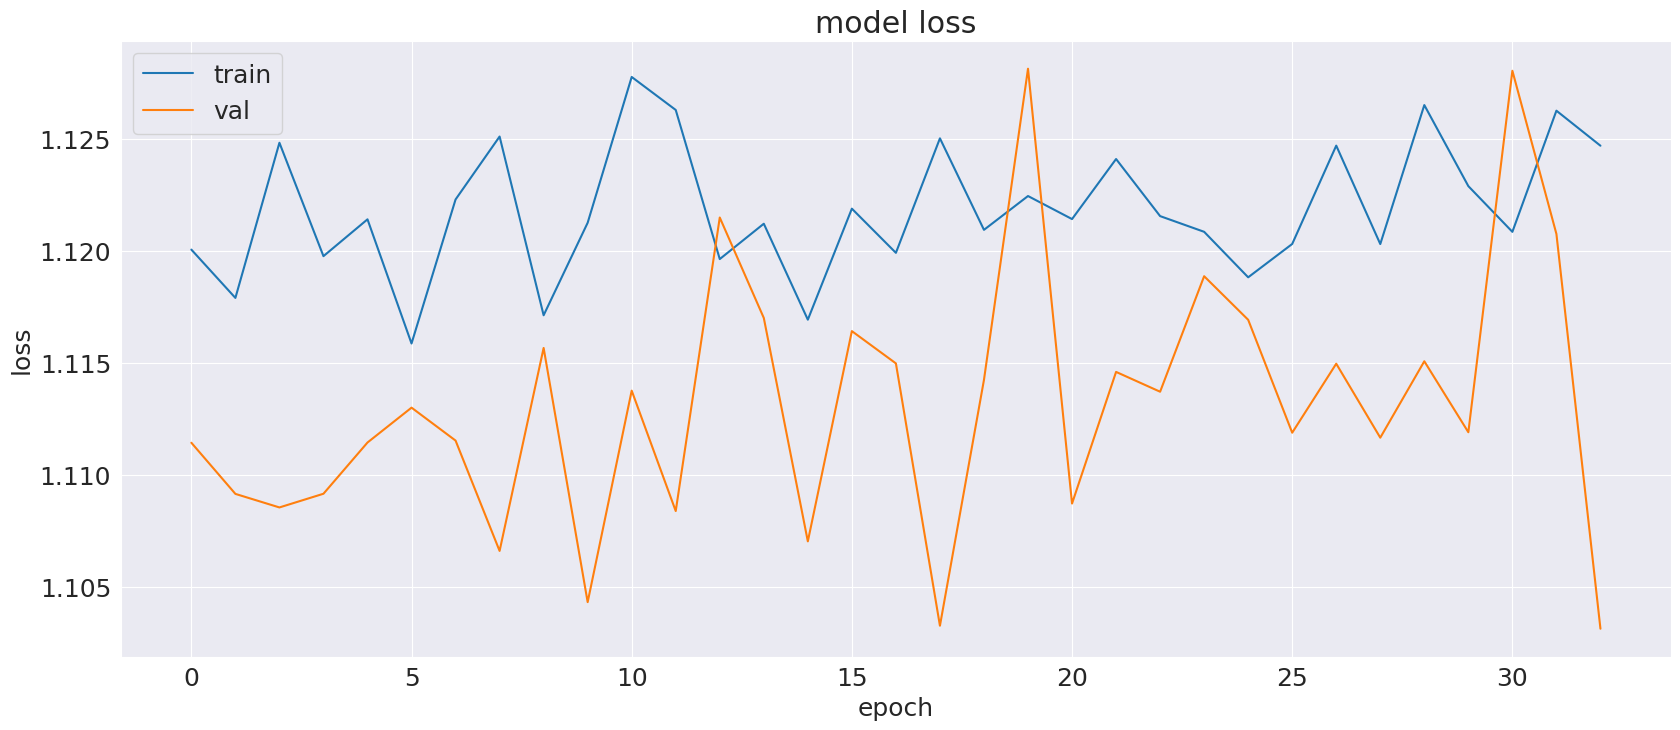

In [ ]:
plt.figure(figsize=(20,8))
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

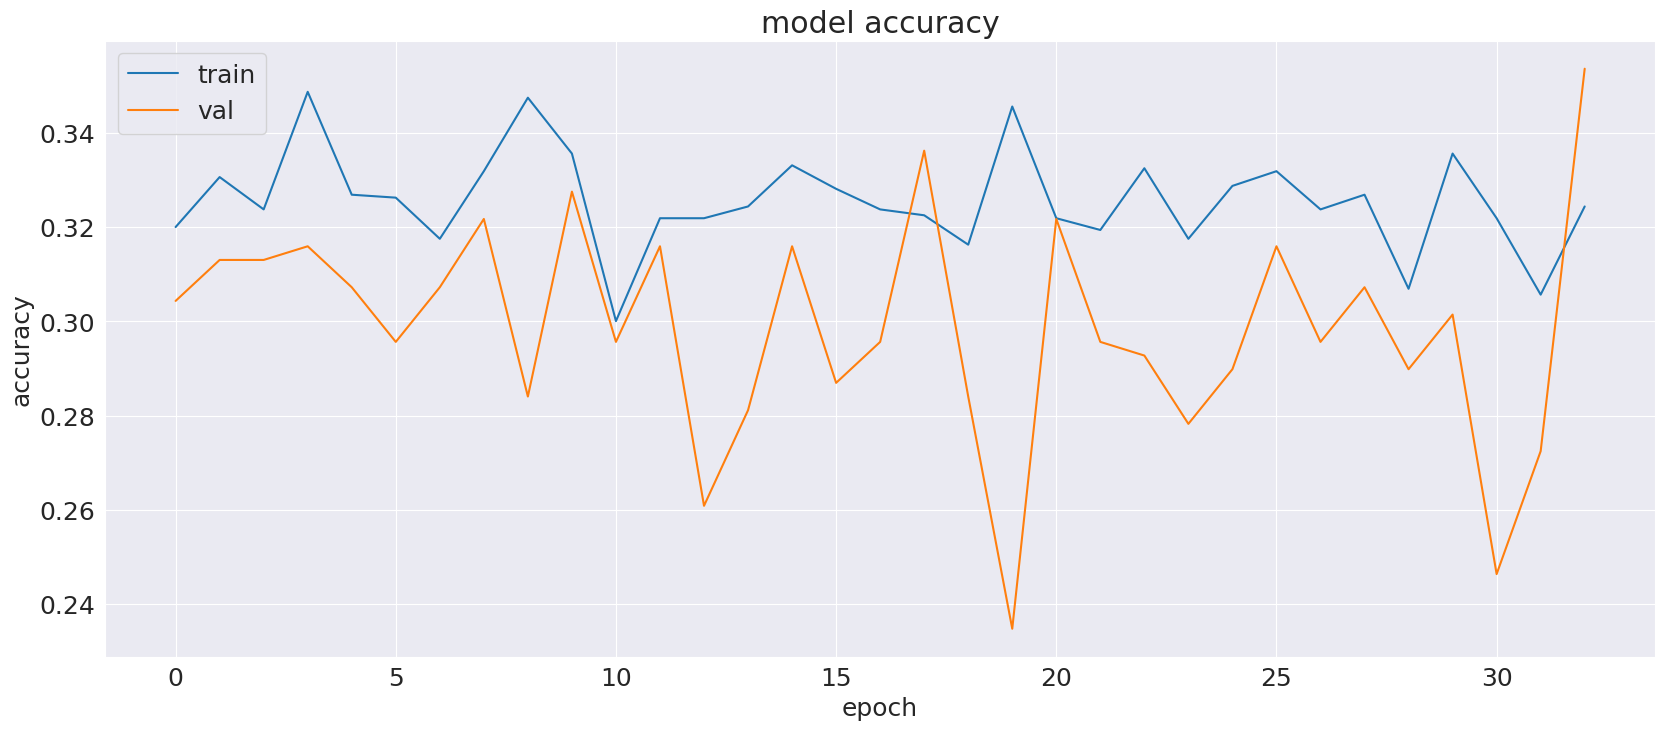

In [ ]:
plt.figure(figsize=(20,8))
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

### Classification Tas

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score
from numpy import argmax
y_pred = model.predict(test_ds)

dict = {}
target = []
pred = []

for tr in test_ds.unbatch().as_numpy_iterator():
  target.append(tr[1])

for pr in y_pred:
  res = [0, 0, 0]
  res[argmax(pr)] = 1.0
  pred.append(res)


6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 70ms/step


In [ ]:


print(classification_report(target, pred))


              precision    recall  f1-score   support

           0       0.33      1.00      0.49       112
           1       0.00      0.00      0.00       118
           2       0.00      0.00      0.00       113

   micro avg       0.33      0.33      0.33       343
   macro avg       0.11      0.33      0.16       343
weighted avg       0.11      0.33      0.16       343
 samples avg       0.33      0.33      0.33       343



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
